# Identificación de zonas de sismicidad de Bolivia mediante aprendizaje no supervisado

**Consenso entre algoritmos: K-Means vs. Ward**

- Catálogo sísmico: USGS Earthquake Hazards Program (API pública FDSN)
- Metodología: CRISP-DM
- Semilla aleatoria: 42
- Ventana temporal: 1973-01-01 a 2026-09-30
- TODA MAGNITUD



## 1. Comprensión del negocio

**Paso 1.1 — Objetivo.** Zonificar de forma cuantitativa y reproducible la sismicidad de Bolivia mediante aprendizaje no supervisado, como insumo para la ingeniería y la gestión del riesgo sísmico.

**Paso 1.2 — Pregunta de investigación.** ¿Es posible identificar regiones sísmicas homogéneas en Bolivia utilizando únicamente la distribución tridimensional de los datos históricos (latitud, longitud y profundidad)?


## 2. Comprensión de los datos



In [1]:
import io
import os
import warnings
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

os.makedirs("resultados/figuras", exist_ok=True)
os.makedirs("resultados/tablas", exist_ok=True)

CIUDADES = {
    "La Paz": (-68.15, -16.50),
    "Cochabamba": (-66.16, -17.39),
    "Santa Cruz": (-63.18, -17.78),
    "Sucre": (-65.26, -19.03),
    "Trinidad": (-64.90, -14.83),
}

def guardar_figura(figura, nombre):
    ruta = f"resultados/figuras/{nombre}.png"
    figura.savefig(ruta, dpi=300, bbox_inches="tight")
    return ruta

def formatear_flotante(v, precision):
    texto = f"{v:.{precision}f}"
    if float(texto) == 0.0:
        texto = texto.lstrip("-")
    return texto

def guardar_tabla(df, nombre, precision=3, ancho_columna_larga="6cm"):
    columnas_originales = list(df.columns)
    columnas_latex = [str(c).replace("_", " ") for c in columnas_originales]

    cuerpo = df.copy()

    for c in cuerpo.columns:
        if pd.api.types.is_float_dtype(cuerpo[c]):
            cuerpo[c] = cuerpo[c].map(lambda v: formatear_flotante(v, precision))

    alineacion = ""
    for i, col in enumerate(columnas_originales):
        max_len = cuerpo[col].astype(str).str.len().max()

        if i == 0:
            alineacion += "l"  # Primera columna siempre a la izquierda
        elif max_len > 30:
            alineacion += f"p{{{ancho_columna_larga}}}"  # Texto largo
        else:
            alineacion += "c"  # Texto corto centrado

    lineas = [
        r"\begin{tabular}{" + alineacion + "}",
        r"\toprule",
        " & ".join(columnas_latex) + r" \\",
        r"\midrule",
    ]
    for _, fila in cuerpo.iterrows():
        lineas.append(" & ".join(str(v) for v in fila.values) + r" \\")
    lineas.append(r"\bottomrule")
    lineas.append(r"\end{tabular}")

    with open(f"resultados/tablas/{nombre}.tex", "w", encoding="utf-8") as f:
        f.write("\n".join(lineas))

    return f"resultados/tablas/{nombre}.tex"

def limites_mapa(longitudes, latitudes):
    lons_ciudades = [v[0] for v in CIUDADES.values()]
    lats_ciudades = [v[1] for v in CIUDADES.values()]
    x_min = min(float(longitudes.min()), min(lons_ciudades)) - 0.4
    x_max = max(float(longitudes.max()), max(lons_ciudades)) + 1.2
    y_min = min(float(latitudes.min()), min(lats_ciudades)) - 0.4
    y_max = max(float(latitudes.max()), max(lats_ciudades)) + 0.4
    return (x_min, x_max), (y_min, y_max)


In [2]:
!python --version
!pip show matplotlib numpy pandas requests scipy seaborn scikit-learn geopandas | grep -E "^Name:|^Version:"

Python 3.13.18
Name: matplotlib
Version: 3.10.0
Name: numpy
Version: 2.4.6
Name: pandas
Version: 2.2.3
Name: requests
Version: 2.32.4
Name: scipy
Version: 1.16.3
Name: seaborn
Version: 0.13.2
Name: scikit-learn
Version: 1.6.1
Name: geopandas
Version: 1.2.0


In [3]:
URL = "https://earthquake.usgs.gov/fdsnws/event/1/query"
PARAMETROS = {
    "format": "csv",
    "starttime": "1973-01-01",
    "endtime": "2026-09-30",
    "minlatitude": -23.0,
    "maxlatitude": -9.6,
    "minlongitude": -69.7,
    "maxlongitude": -57.4,
    "minmagnitude": 0,
    "eventtype": "earthquake",
    "orderby": "time-asc",
}
ANIOS = f"{PARAMETROS['starttime'][:4]}-{PARAMETROS['endtime'][:4]}"
respuesta = requests.get(URL, params=PARAMETROS, timeout=300)
respuesta.raise_for_status()
catalogo = pd.read_csv(io.StringIO(respuesta.text))
catalogo["fecha"] = pd.to_datetime(catalogo["time"], utc=True)
catalogo.to_csv("resultados/catalogo_crudo_usgs.csv", index=False)
print(f"Eventos descargados: {len(catalogo)}")
print("Catálogo crudo almacenado en resultados/catalogo_crudo_usgs.csv")


Eventos descargados: 7704
Catálogo crudo almacenado en resultados/catalogo_crudo_usgs.csv


In [4]:
url_mapa = "https://raw.githubusercontent.com/johan/world.geo.json/master/countries.geo.json"
world = gpd.read_file(url_mapa)

bolivia_poly = world[world['name'] == 'Bolivia']

gdf_sismos = gpd.GeoDataFrame(
    catalogo,
    geometry=gpd.points_from_xy(catalogo.longitude, catalogo.latitude),
    crs="EPSG:4326"
)

# 4. Cruce espacial: se conservan solo los puntos dentro (within) de Bolivia
gdf_sismos_bolivia = gpd.sjoin(gdf_sismos, bolivia_poly, how="inner", predicate="within")

columnas_innecesarias = ['geometry', 'index_right', 'id', 'name', 'id_left', 'id_right']
catalogo_bolivia = pd.DataFrame(gdf_sismos_bolivia.drop(columns=columnas_innecesarias, errors='ignore'))

catalogo_bolivia.to_csv("resultados/catalogo_bolivia_estricto.csv", index=False)

TOTAL_REGIONAL = len(catalogo)

print(f"Eventos originales (con países vecinos): {len(catalogo)}")
print(f"Eventos estrictamente dentro de Bolivia: {len(catalogo_bolivia)}")

catalogo = catalogo_bolivia


Eventos originales (con países vecinos): 7704
Eventos estrictamente dentro de Bolivia: 2323


### Paso 2.2 — Análisis exploratorio de datos (EDA)

Se verifica cuántos sismos componen la base, el rango de magnitudes y el comportamiento de las variables clave: latitud, longitud y profundidad.


In [5]:
resumen_catalogo = pd.DataFrame({
    "Indicador": [
        "Eventos totales",
        "Fecha inicial",
        "Fecha final",
        "Magnitud minima",
        "Magnitud maxima",
        "Profundidad minima (km)",
        "Profundidad maxima (km)",
    ],
    "Valor": [
        str(len(catalogo)),
        str(catalogo["fecha"].min().date()),
        str(catalogo["fecha"].max().date()),
        f"{catalogo['mag'].min():.1f}",
        f"{catalogo['mag'].max():.1f}",
        f"{catalogo['depth'].min():.1f}",
        f"{catalogo['depth'].max():.1f}",
    ],
})
guardar_tabla(resumen_catalogo, "tabla_01_resumen_catalogo")
resumen_catalogo


,Indicador,Valor
0,Eventos totales,2323
1,Fecha inicial,1973-02-07
2,Fecha final,2026-09-29
3,Magnitud minima,0.0
4,Magnitud maxima,8.2
5,Profundidad minima (km),3.4
6,Profundidad maxima (km),650.0


In [6]:
estadisticos = catalogo[["latitude", "longitude", "depth", "mag"]].describe().T.reset_index()
estadisticos.columns = ["Variable", "N", "Media", "Desv. est.", "Min", "Q1", "Mediana", "Q3", "Max"]
estadisticos["Variable"] = ["Latitud", "Longitud", "Profundidad (km)", "Magnitud"]
estadisticos["N"] = estadisticos["N"].astype(int)
guardar_tabla(estadisticos, "tabla_02_estadisticos_descriptivos", precision=2)
estadisticos


,Variable,N,Media,Desv. est.,Min,Q1,Mediana,Q3,Max
0,Latitud,2323,-20.337225,1.703774,-22.8146,-21.4985,-20.992,-19.1440,-13.682
1,Longitud,2323,-67.336615,1.284472,-69.5550,-68.1635,-67.384,-66.7846,-62.917
2,Profundidad (km),2323,184.963842,92.366027,3.3800,140.5000,181.500,222.7635,650.000
3,Magnitud,2323,4.267585,0.900782,0.0000,4.1000,4.300,4.6000,8.200


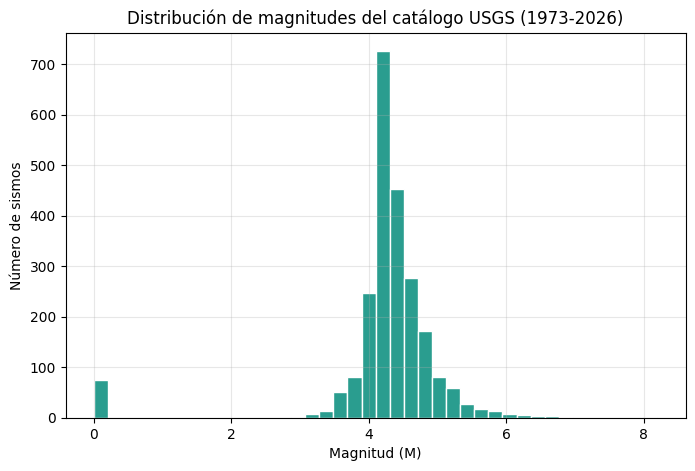

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(catalogo["mag"], bins=40, color="#2a9d8f", edgecolor="white")
ax.set_xlabel("Magnitud (M)")
ax.set_ylabel("Número de sismos")
ax.set_title(f"Distribución de magnitudes del catálogo USGS ({ANIOS})")
ax.grid(alpha=0.3)
guardar_figura(fig, "figura_01_histograma_magnitudes")
plt.show()


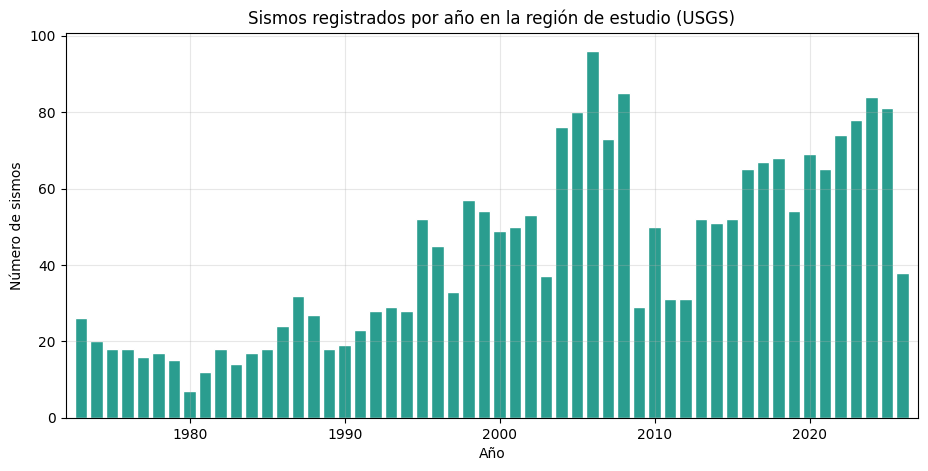

In [8]:
eventos_anio = catalogo["fecha"].dt.year.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(eventos_anio.index, eventos_anio.values, color="#2a9d8f", edgecolor="white")
ax.set_xlabel("Año")
ax.set_ylabel("Número de sismos")
ax.set_title("Sismos registrados por año en la región de estudio (USGS)")
ax.set_xlim(int(eventos_anio.index.min()) - 1, int(eventos_anio.index.max()) + 1)
ax.grid(alpha=0.3)
guardar_figura(fig, "figura_02_sismos_por_anio")
plt.show()


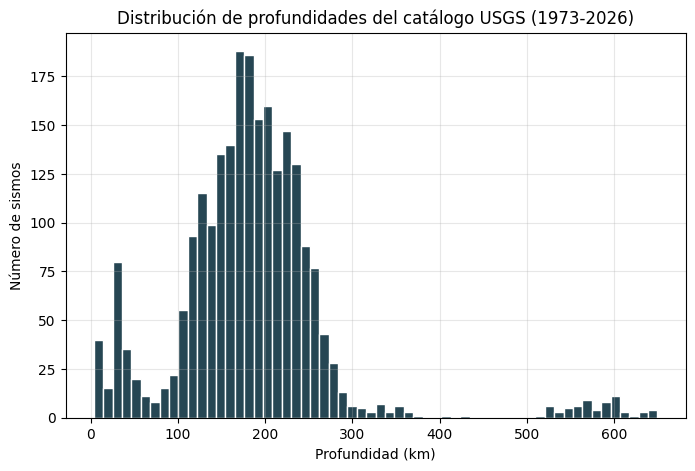

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(catalogo["depth"], bins=60, color="#264653", edgecolor="white")
ax.set_xlabel("Profundidad (km)")
ax.set_ylabel("Número de sismos")
ax.set_title(f"Distribución de profundidades del catálogo USGS ({ANIOS})")
ax.grid(alpha=0.3)
guardar_figura(fig, "figura_03_histograma_profundidades")
plt.show()


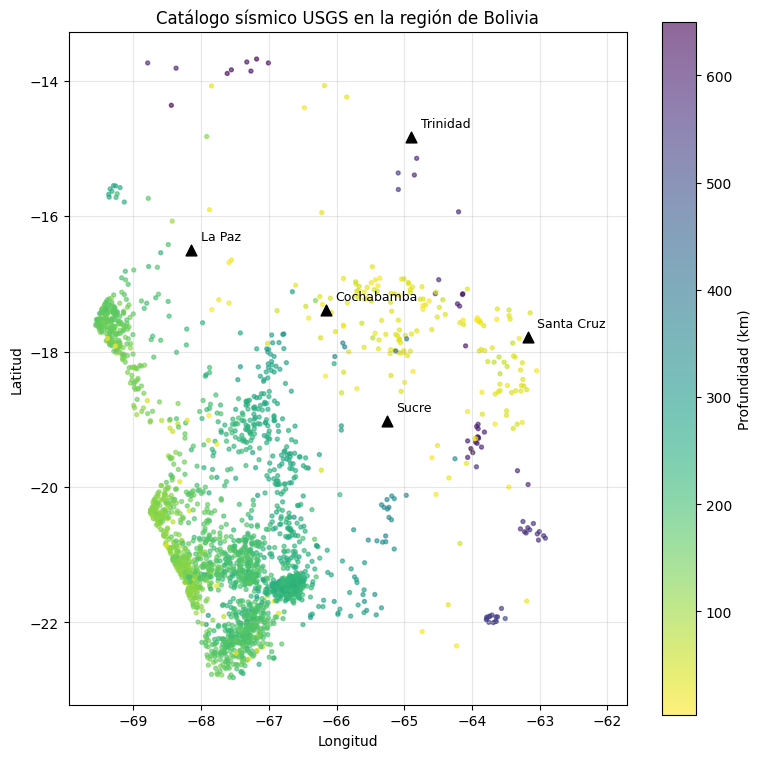

In [10]:
fig, ax = plt.subplots(figsize=(9, 9))
puntos = ax.scatter(
    catalogo["longitude"],
    catalogo["latitude"],
    c=catalogo["depth"],
    cmap="viridis_r",
    s=8,
    alpha=0.6,
)
fig.colorbar(puntos, ax=ax, label="Profundidad (km)")
for nombre, (lon, lat) in CIUDADES.items():
    ax.scatter(lon, lat, marker="^", color="black", s=60)
    ax.annotate(nombre, (lon, lat), textcoords="offset points", xytext=(7, 7), fontsize=9)
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title("Catálogo sísmico USGS en la región de Bolivia")
xlim, ylim = limites_mapa(catalogo["longitude"], catalogo["latitude"])
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.set_aspect("equal")
ax.grid(alpha=0.3)
guardar_figura(fig, "figura_04_mapa_catalogo_completo")
plt.show()


## 3. Preparación de los datos

**Paso 3.1 — Filtro base.** Se seleccionan los sismos con magnitud mayor o igual a 4.0 para garantizar que los datos sean representativos.

**Paso 3.2 — Ingeniería de características.** Se estandarizan las tres variables espaciales con `StandardScaler`: latitud, longitud y profundidad. Esto asegura que la profundidad (en kilómetros) no distorsione el peso de la latitud y la longitud en el cálculo de las distancias euclidianas.

**Paso 3.3 — Verificación del agrupamiento espacial.** Se calcula el índice de Morisita sobre las coordenadas de los epicentros, con cuadrículas de 4x4 a 16x16 celdas. Valores del índice mayores que 1 confirman que la distribución es agrupada y que el agrupamiento automático está justificado.

In [11]:
datos = catalogo[["latitude", "longitude", "depth", "mag", "fecha"]].copy()
datos = datos.rename(
    columns={
        "latitude": "latitud",
        "longitude": "longitud",
        "depth": "profundidad_km",
        "mag": "magnitud",
    }
)
datos = datos.dropna(subset=["latitud", "longitud", "profundidad_km", "magnitud"])
datos_filtrados = datos[datos["magnitud"] >= 0].copy().reset_index(drop=True)


In [12]:
tabla_filtro = pd.DataFrame({
    "Etapa": [
        "Catálogo regional (caja envolvente)",
        "Dentro de Bolivia (filtro espacial)",
        "Sin valores perdidos",
        "Con magnitud mayor o igual a 0",
    ],
    "Sismos": [TOTAL_REGIONAL, len(catalogo), len(datos), len(datos_filtrados)],
})
guardar_tabla(tabla_filtro, "tabla_03_filtro_catalogo")
tabla_filtro


,Etapa,Sismos
0,Catálogo regional (caja envolvente),7704
1,Dentro de Bolivia (filtro espacial),2323
2,Sin valores perdidos,2323
3,Con magnitud mayor o igual a 0,2323


In [13]:
caracteristicas = datos_filtrados[["latitud", "longitud", "profundidad_km"]]
escalador = StandardScaler()
X = escalador.fit_transform(caracteristicas)


In [14]:
verificacion = pd.DataFrame({
    "Variable": ["Latitud (z)", "Longitud (z)", "Profundidad (z)"],
    "Media": X.mean(axis=0),
    "Desv_estandar": X.std(axis=0, ddof=0),
})
guardar_tabla(verificacion, "tabla_04_verificacion_estandarizacion", precision=4)
verificacion


,Variable,Media,Desv_estandar
0,Latitud (z),-4.343395e-16,1.0
1,Longitud (z),6.851553e-16,1.0
2,Profundidad (z),2.446983e-17,1.0


In [15]:
# VERIFICACIÓN DEL AGRUPAMIENTO ESPACIAL: ÍNDICE DE MORISITA

def calcular_morisita(df, divisiones_lat, divisiones_lon):
    """Calcula el índice de Morisita del conjunto de epicentros."""
    N = len(df)
    if N <= 1:
        return 0.0

    lat_bins = np.linspace(df["latitud"].min(), df["latitud"].max(), divisiones_lat + 1)
    lon_bins = np.linspace(df["longitud"].min(), df["longitud"].max(), divisiones_lon + 1)

    cuadrantes, _, _ = np.histogram2d(df["latitud"], df["longitud"], bins=[lat_bins, lon_bins])

    Q = divisiones_lat * divisiones_lon
    suma_pares = np.sum(cuadrantes * (cuadrantes - 1))
    return Q * (suma_pares / (N * (N - 1)))

divisiones = [4, 8, 12, 16]
resultados_morisita = []

for q in divisiones:
    indice = calcular_morisita(datos_filtrados, q, q)
    resultados_morisita.append({
        "Cuadrícula": f"{q}x{q}",
        "Cuadrantes": q ** 2,
        "Índice_Morisita": round(indice, 4),
    })

df_morisita = pd.DataFrame(resultados_morisita)
guardar_tabla(df_morisita, "tabla_04b_indice_morisita", precision=4)

print("=== ÍNDICE DE MORISITA: VERIFICACIÓN DEL AGRUPAMIENTO ESPACIAL ===\n")
print(df_morisita.to_string(index=False))
print("\nRegla de interpretación: valores mayores que 1 indican distribución agrupada,")
print("el valor 1 corresponde a una distribución aleatoria y valores menores que 1 a una uniforme.")


=== ÍNDICE DE MORISITA: VERIFICACIÓN DEL AGRUPAMIENTO ESPACIAL ===

Cuadrícula  Cuadrantes  Índice_Morisita
       4x4          16           3.8688
       8x8          64           5.8408
     12x12         144           6.3315
     16x16         256           7.8903

Regla de interpretación: valores mayores que 1 indican distribución agrupada,
el valor 1 corresponde a una distribución aleatoria y valores menores que 1 a una uniforme.


## 4. Modelado

**Paso 4.1 — Modelo línea base.** Se ejecuta K-Means y se evalúa el número de zonas con el método del codo (inercia) y el índice de silueta.

**Paso 4.2 — Modelo competitivo.** Se ejecuta el agrupamiento jerárquico con enlace de Ward sobre las mismas variables estandarizadas, con el mismo número de clústeres elegido para K-Means.


In [16]:
rango_k = range(2, 11)
inercias = []
siluetas = []
for k in rango_k:
    modelo = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    etiquetas = modelo.fit_predict(X)
    inercias.append(modelo.inertia_)
    siluetas.append(silhouette_score(X, etiquetas))
metricas_k = pd.DataFrame({
    "K": list(rango_k),
    "Inercia": inercias,
    "Silueta": siluetas,
})


In [17]:
guardar_tabla(metricas_k, "tabla_05_seleccion_k")
metricas_k


,K,Inercia,Silueta
0,2,5111.151578,0.441165
1,3,3579.517761,0.478574
2,4,2217.076674,0.481191
3,5,1577.347764,0.421525
4,6,1199.684500,0.476628
5,7,1020.471282,0.480779
6,8,848.195927,0.455297
7,9,752.500119,0.448217
8,10,678.232332,0.449112


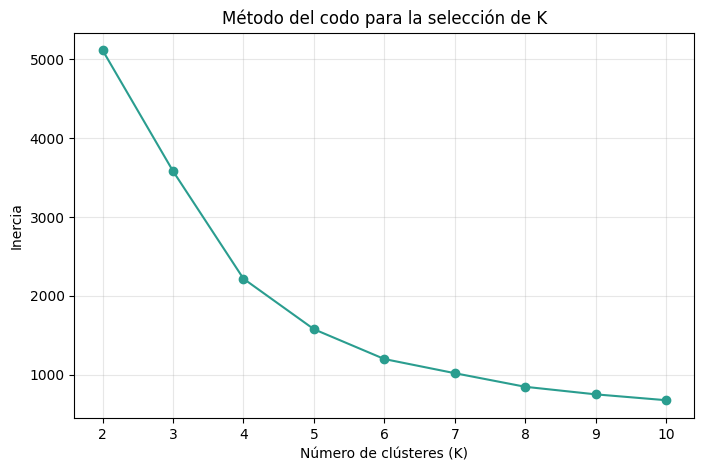

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(metricas_k["K"], metricas_k["Inercia"], marker="o", color="#2a9d8f")
ax.set_xlabel("Número de clústeres (K)")
ax.set_ylabel("Inercia")
ax.set_title("Método del codo para la selección de K")
ax.set_xticks(list(rango_k))
ax.grid(alpha=0.3)
guardar_figura(fig, "figura_05_metodo_codo")
plt.show()


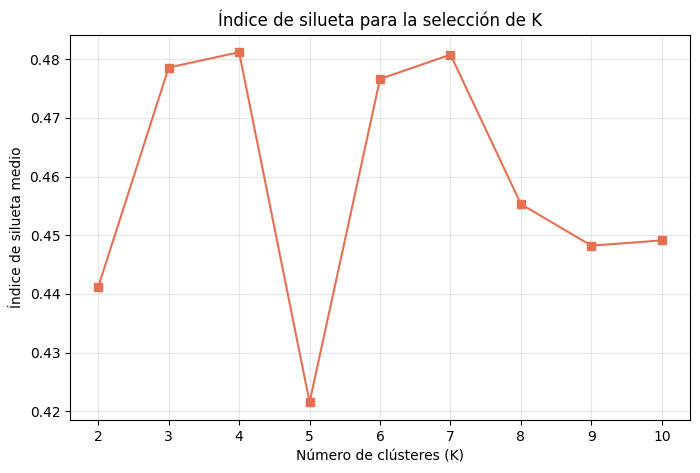

In [19]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(metricas_k["K"], metricas_k["Silueta"], marker="s", color="#e76f51")
ax.set_xlabel("Número de clústeres (K)")
ax.set_ylabel("Índice de silueta medio")
ax.set_title("Índice de silueta para la selección de K")
ax.set_xticks(list(rango_k))
ax.grid(alpha=0.3)
guardar_figura(fig, "figura_06_indice_silueta")
plt.show()


In [20]:
K_OPTIMO = int(metricas_k.loc[metricas_k["Silueta"].idxmax(), "K"])
print("Valores de silueta más altos:")
print(metricas_k.sort_values("Silueta", ascending=False).head(3).to_string(index=False))
print(f"K seleccionado de forma automática: K = {K_OPTIMO}")
kmeans = KMeans(n_clusters=K_OPTIMO, n_init=10, random_state=SEED)
datos_filtrados["zona_kmeans"] = kmeans.fit_predict(X)
print(f"K-Means ajustado con K = {K_OPTIMO}")


Valores de silueta más altos:
 K     Inercia  Silueta
 4 2217.076674 0.481191
 7 1020.471282 0.480779
 3 3579.517761 0.478574
K seleccionado de forma automática: K = 4
K-Means ajustado con K = 4


**Paso 4.3 — Agrupamiento jerárquico Ward.** Se construye el dendrograma y se ajusta el modelo con enlace de Ward, que fusiona los grupos minimizando el incremento de la varianza intra-cluster.


In [21]:
enlace = linkage(X, method="ward")
ward = AgglomerativeClustering(n_clusters=K_OPTIMO, linkage="ward")
datos_filtrados["zona_ward"] = ward.fit_predict(X)
print(f"Ward ajustado con K = {K_OPTIMO}")


Ward ajustado con K = 4


In [22]:
profundidad_media = datos_filtrados.groupby("zona_kmeans")["profundidad_km"].mean()
orden = profundidad_media.sort_values(ascending=False).index.tolist()
mapa_canonico = {zona: numero for numero, zona in enumerate(orden, start=1)}
datos_filtrados["zona_kmeans"] = datos_filtrados["zona_kmeans"].map(mapa_canonico).astype(int)

cruce_previo = pd.crosstab(datos_filtrados["zona_kmeans"], datos_filtrados["zona_ward"])
fila_ind, col_ind = linear_sum_assignment(-cruce_previo.values)
mapa_ward = {cruce_previo.columns[c]: cruce_previo.index[f] for f, c in zip(fila_ind, col_ind)}
datos_filtrados["zona_ward"] = datos_filtrados["zona_ward"].map(mapa_ward).astype(int)

zonas = range(1, K_OPTIMO + 1)
print(f"Numeración canónica aplicada: Zona 1 a Zona {K_OPTIMO}, por profundidad media decreciente")
print("Etiquetas de Ward alineadas con K-Means por emparejamiento óptimo (algoritmo húngaro)")


Numeración canónica aplicada: Zona 1 a Zona 4, por profundidad media decreciente
Etiquetas de Ward alineadas con K-Means por emparejamiento óptimo (algoritmo húngaro)


**Numeración canónica y alineación de particiones.** Las etiquetas de un algoritmo de agrupamiento son arbitrarias: el mismo agrupamiento puede recibir números distintos en cada ejecución y entre algoritmos. Para que las tablas y los mapas sean comparables se aplican dos operaciones. Primero, las zonas de K-Means se renumeran con una regla determinista: la Zona 1 es la de mayor profundidad media y la numeración sigue en orden decreciente de profundidad. Segundo, las zonas de Ward se emparejan con las de K-Means mediante el algoritmo húngaro, que maximiza el número de sismos coincidentes en la matriz de cruce. Ninguna de las dos operaciones altera la geometría de las zonas ni el valor del ARI: solo hacen legible la comparación.


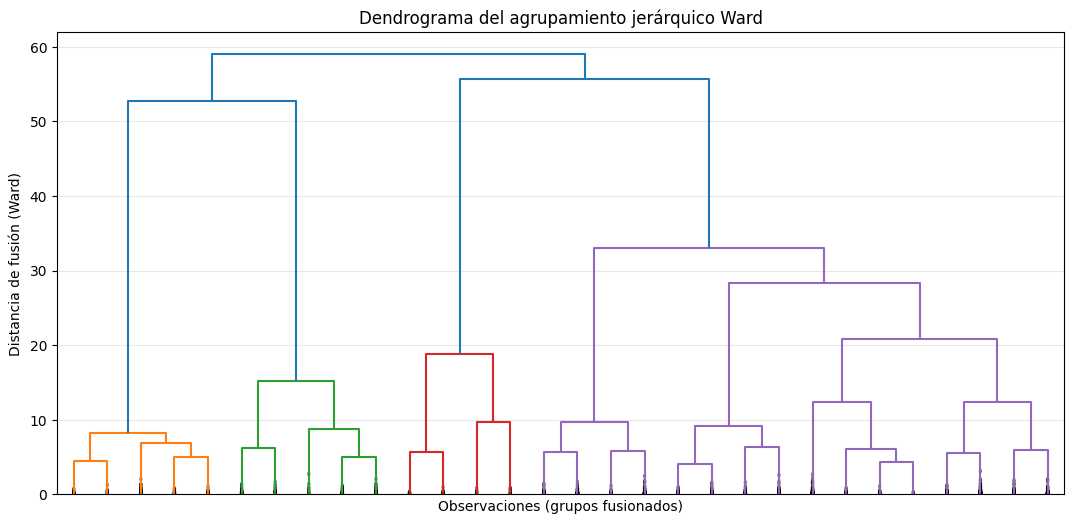

In [23]:
fig, ax = plt.subplots(figsize=(13, 6))
dendrogram(enlace, truncate_mode="lastp", p=30, show_contracted=True, ax=ax, no_labels=True)
ax.set_xlabel("Observaciones (grupos fusionados)")
ax.set_ylabel("Distancia de fusión (Ward)")
ax.set_title("Dendrograma del agrupamiento jerárquico Ward")
ax.grid(alpha=0.3, axis="y")
guardar_figura(fig, "figura_07_dendrograma_ward")
plt.show()


In [24]:
tamanos = pd.DataFrame({
    "Zona": [f"Zona {i}" for i in zonas],
    "K-Means": datos_filtrados["zona_kmeans"].value_counts().sort_index().values,
    "Ward": datos_filtrados["zona_ward"].value_counts().sort_index().values,
})
guardar_tabla(tamanos, "tabla_06_tamanos_clusters")
tamanos


,Zona,K-Means,Ward
0,Zona 1,77,64
1,Zona 2,1536,1802
2,Zona 3,540,278
3,Zona 4,170,179


In [25]:
centroides = (
    datos_filtrados.groupby("zona_kmeans")
    .agg(
        Sismos=("magnitud", "size"),
        Latitud=("latitud", "mean"),
        Longitud=("longitud", "mean"),
        Profundidad_km=("profundidad_km", "mean"),
    )
    .reset_index()
)
centroides.insert(0, "Zona", [f"Zona {i}" for i in centroides["zona_kmeans"]])
centroides = centroides.drop(columns=["zona_kmeans"])
guardar_tabla(centroides, "tabla_07_centroides_kmeans", precision=2)
centroides


,Zona,Sismos,Latitud,Longitud,Profundidad_km
0,Zona 1,77,-18.949991,-64.499275,543.035208
1,Zona 2,1536,-21.312516,-67.330328,191.221571
2,Zona 3,540,-18.529453,-68.581756,163.908180
3,Zona 4,170,-17.895849,-64.723412,33.120847


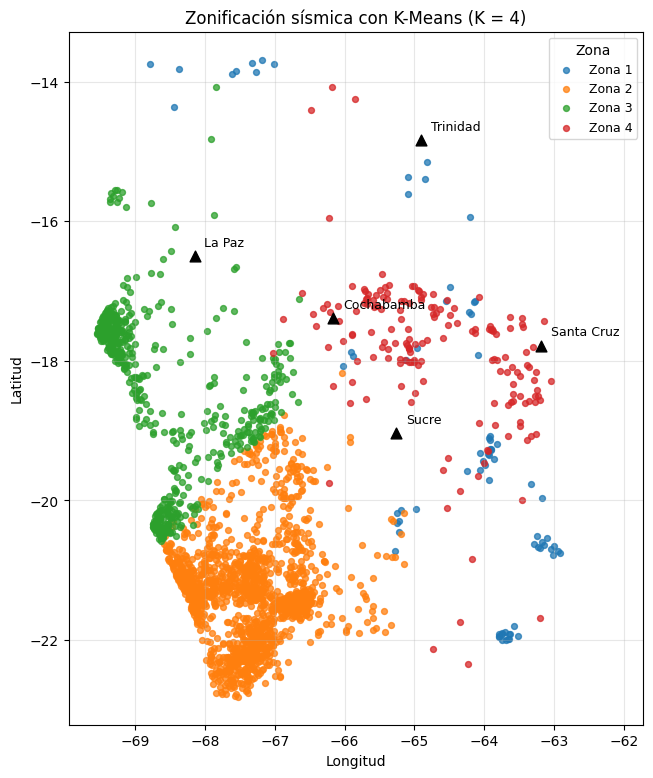

In [26]:
fig, ax = plt.subplots(figsize=(9, 9))
for zona in zonas:
    sub = datos_filtrados[datos_filtrados["zona_kmeans"] == zona]
    ax.scatter(sub["longitud"], sub["latitud"], s=18, alpha=0.75, label=f"Zona {zona}")
for nombre, (lon, lat) in CIUDADES.items():
    ax.scatter(lon, lat, marker="^", color="black", s=60)
    ax.annotate(nombre, (lon, lat), textcoords="offset points", xytext=(7, 7), fontsize=9)
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title(f"Zonificación sísmica con K-Means (K = {K_OPTIMO})")
xlim, ylim = limites_mapa(datos_filtrados["longitud"], datos_filtrados["latitud"])
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.set_aspect("equal")
ax.grid(alpha=0.3)
ax.legend(title="Zona", loc="best", fontsize=9)
guardar_figura(fig, "figura_08_mapa_kmeans")
plt.show()


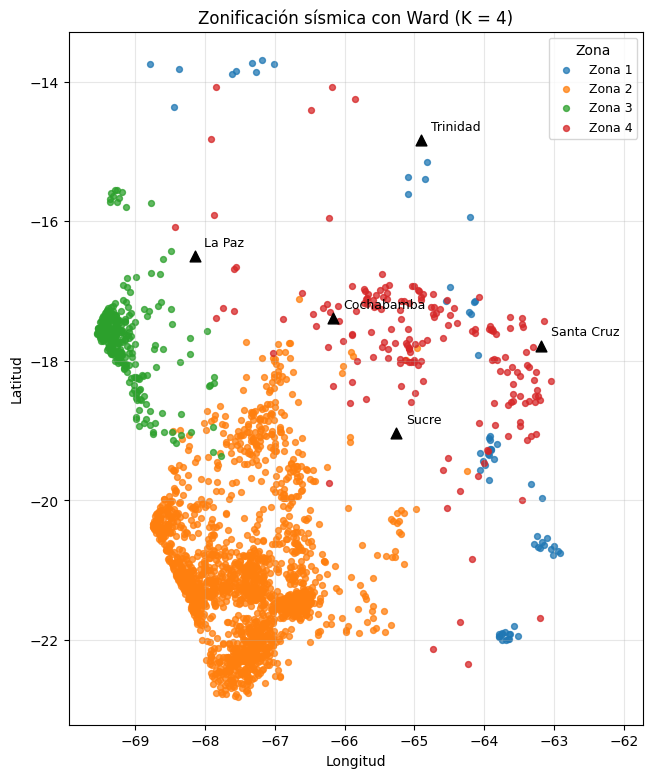

In [27]:
fig, ax = plt.subplots(figsize=(9, 9))
for zona in zonas:
    sub = datos_filtrados[datos_filtrados["zona_ward"] == zona]
    ax.scatter(sub["longitud"], sub["latitud"], s=18, alpha=0.75, label=f"Zona {zona}")
for nombre, (lon, lat) in CIUDADES.items():
    ax.scatter(lon, lat, marker="^", color="black", s=60)
    ax.annotate(nombre, (lon, lat), textcoords="offset points", xytext=(7, 7), fontsize=9)
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title(f"Zonificación sísmica con Ward (K = {K_OPTIMO})")
xlim, ylim = limites_mapa(datos_filtrados["longitud"], datos_filtrados["latitud"])
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.set_aspect("equal")
ax.grid(alpha=0.3)
ax.legend(title="Zona", loc="best", fontsize=9)
guardar_figura(fig, "figura_09_mapa_ward")
plt.show()


## 5. Evaluación — Estrategia de consenso

**Paso 5.1 — Validación cruzada externa.** Se calcula el índice Adjusted Rand Index (ARI) para medir el grado de concordancia matemática entre las particiones generadas por K-Means y por Ward.


In [28]:
ari = adjusted_rand_score(datos_filtrados["zona_kmeans"], datos_filtrados["zona_ward"])
tabla_ari = pd.DataFrame({
    "Indicador": ["Adjusted Rand Index (ARI)"],
    "Valor": [ari],
})
guardar_tabla(tabla_ari, "tabla_08_ari", precision=4)
tabla_ari


,Indicador,Valor
0,Adjusted Rand Index (ARI),0.637571


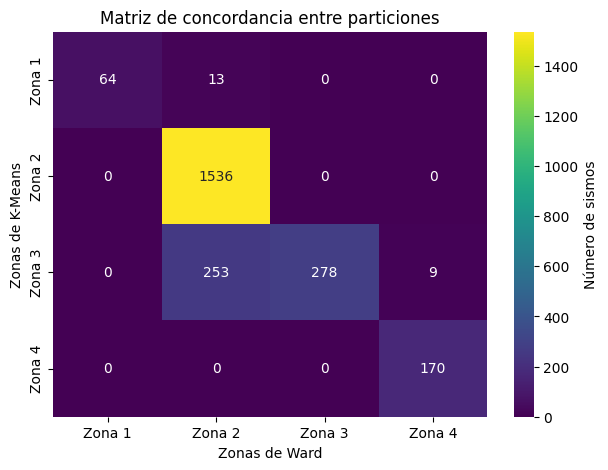

In [29]:
cruce = pd.crosstab(datos_filtrados["zona_kmeans"], datos_filtrados["zona_ward"])
cruce.index = [f"Zona {i}" for i in cruce.index]
cruce.columns = [f"Zona {j}" for j in cruce.columns]
cruce.index.name = "Zona K-Means"
cruce.columns.name = "Zona Ward"
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cruce, annot=True, fmt="d", cmap="viridis", ax=ax, cbar_kws={"label": "Número de sismos"})
ax.set_xlabel("Zonas de Ward")
ax.set_ylabel("Zonas de K-Means")
ax.set_title("Matriz de concordancia entre particiones")
guardar_figura(fig, "figura_10_matriz_concordancia")
plt.show()


In [30]:
concordancia = cruce.reset_index()
concordancia.columns = ["Zona K-Means"] + [f"Ward {col}" for col in cruce.columns]
guardar_tabla(concordancia, "tabla_09_concordancia_kmeans_ward")
coinciden = int(np.diag(cruce.values).sum())
total = int(cruce.values.sum())
print(f"ARI: {ari:.4f}")
print(f"Sismos en la zona equivalente tras la alineación: {coinciden} de {total} ({100 * coinciden / total:.1f} por ciento)")
print(cruce.to_string())
concordancia


ARI: 0.6376
Sismos en la zona equivalente tras la alineación: 2048 de 2323 (88.2 por ciento)
Zona Ward     Zona 1  Zona 2  Zona 3  Zona 4
Zona K-Means                                
Zona 1            64      13       0       0
Zona 2             0    1536       0       0
Zona 3             0     253     278       9
Zona 4             0       0       0     170


,Zona K-Means,Ward Zona 1,Ward Zona 2,Ward Zona 3,Ward Zona 4
0,Zona 1,64,13,0,0
1,Zona 2,0,1536,0,0
2,Zona 3,0,253,278,9
3,Zona 4,0,0,0,170


**Paso 5.2 — Interpretación de robustez.** El ARI corrige el acuerdo esperado por puro azar y se interpreta de la siguiente manera:

- ARI superior a 0.75: fronteras espaciales robustas, alto consenso entre algoritmos.
- ARI entre 0.5 y 0.75: acuerdo moderado, atribuible a la diferencia geométrica entre ambos criterios (K-Means produce particiones de Voronoi, Ward fusiona jerárquicamente con mínima varianza).
- ARI inferior a 0.5: particiones divergentes; se analiza la diferencia sin invalidar la zonificación.



## 6. Despliegue

**Paso 6.1 — Insumo para decisiones.** Mapas finales lado a lado con las zonas sísmicas identificadas y resumen estadístico por zona.

**Paso 6.2 — Trazabilidad y cierre.** El pipeline es auditable y reproducible: al reejecutarse descarga el catálogo dentro de la ventana definida, guarda el catálogo crudo junto con las figuras y las tablas, y regenera todos los artefactos de forma automática. La semilla fija y la numeración canónica de zonas garantizan que una reejecución produzca particiones comparables.


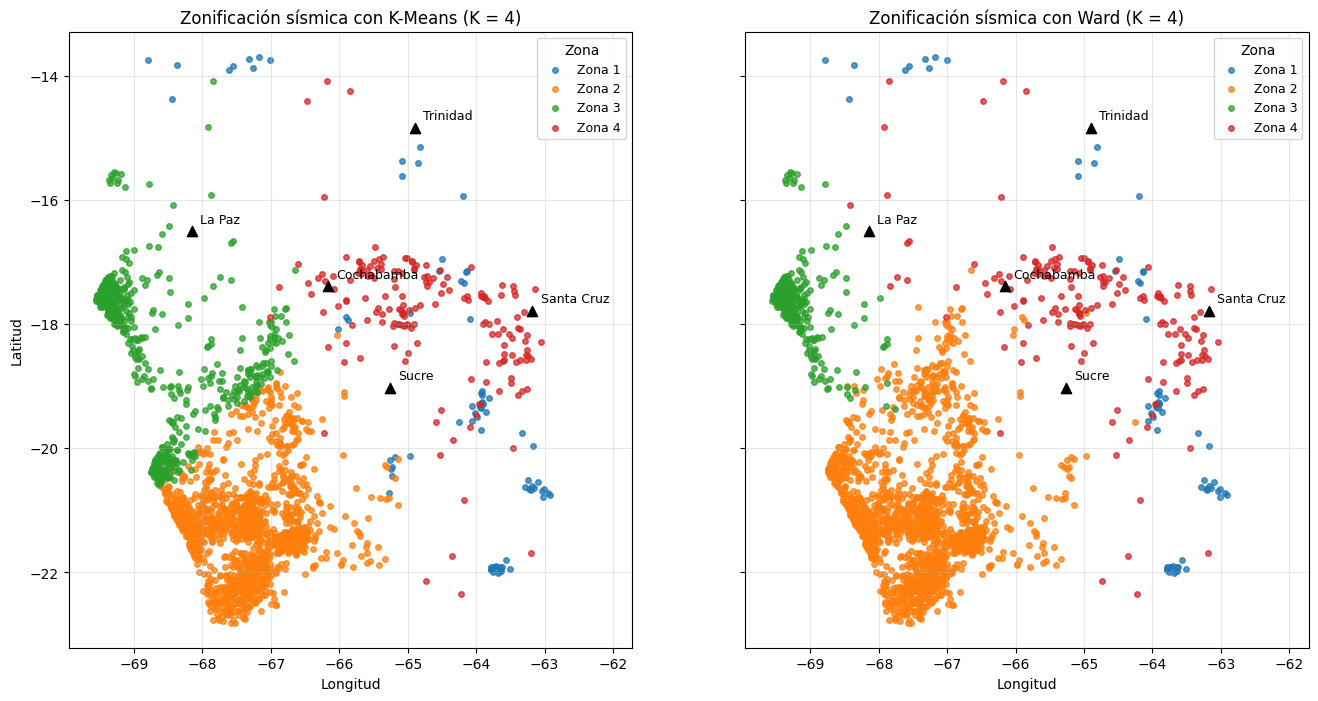

In [31]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)
xlim, ylim = limites_mapa(datos_filtrados["longitud"], datos_filtrados["latitud"])
for eje, columna, titulo in zip(ejes, ["zona_kmeans", "zona_ward"], ["K-Means", "Ward"]):
    for zona in zonas:
        sub = datos_filtrados[datos_filtrados[columna] == zona]
        eje.scatter(sub["longitud"], sub["latitud"], s=16, alpha=0.75, label=f"Zona {zona}")
    for nombre, (lon, lat) in CIUDADES.items():
        eje.scatter(lon, lat, marker="^", color="black", s=55)
        eje.annotate(nombre, (lon, lat), textcoords="offset points", xytext=(6, 6), fontsize=9)
    eje.set_title(f"Zonificación sísmica con {titulo} (K = {K_OPTIMO})")
    eje.set_xlabel("Longitud")
    eje.set_xlim(xlim)
    eje.set_ylim(ylim)
    eje.grid(alpha=0.3)
    eje.legend(title="Zona", loc="best", fontsize=9)
ejes[0].set_ylabel("Latitud")
guardar_figura(fig, "figura_11_mapa_comparativo")
plt.show()


In [32]:
bloques = []
for modelo, columna in [("K-Means", "zona_kmeans"), ("Ward", "zona_ward")]:
    bloque = (
        datos_filtrados.groupby(columna)
        .agg(
            Sismos=("magnitud", "size"),
            Magnitud_media=("magnitud", "mean"),
            Profundidad_media_km=("profundidad_km", "mean"),
            Latitud_media=("latitud", "mean"),
            Longitud_media=("longitud", "mean"),
        )
        .reset_index()
    )
    bloque.insert(0, "Modelo", modelo)
    bloque = bloque.rename(columns={columna: "Zona"})
    bloque["Zona"] = bloque["Zona"].map(lambda z: f"Zona {z}")
    bloques.append(bloque)
resumen_zonas = pd.concat(bloques, ignore_index=True)
resumen_zonas = resumen_zonas[
    ["Modelo", "Zona", "Sismos", "Magnitud_media", "Profundidad_media_km", "Latitud_media", "Longitud_media"]
]
guardar_tabla(resumen_zonas, "tabla_10_resumen_zonas", precision=2)
resumen_zonas


,Modelo,Zona,Sismos,Magnitud_media,Profundidad_media_km,Latitud_media,Longitud_media
0,K-Means,Zona 1,77,4.772727,543.035208,-18.949991,-64.499275
1,K-Means,Zona 2,1536,4.226628,191.221571,-21.312516,-67.330328
2,K-Means,Zona 3,540,4.291111,163.908180,-18.529453,-68.581756
3,K-Means,Zona 4,170,4.334118,33.120847,-17.895849,-64.723412
4,Ward,Zona 1,64,4.785938,579.352156,-18.869359,-64.342175
5,Ward,Zona 2,1802,4.238790,190.746687,-21.048750,-67.408066
6,Ward,Zona 3,278,4.296043,154.312313,-17.688739,-69.145224
7,Ward,Zona 4,179,4.327933,33.341419,-17.812383,-64.879054


In [33]:
tabla_pipeline = pd.DataFrame({
    "Parametro": [
        "Fuente de datos",
        "Ventana temporal",
        "Caja envolvente (latitud)",
        "Caja envolvente (longitud)",
        "Magnitud minima de descarga",
        "Magnitud minima de modelado",
        "Variables de agrupamiento",
        "Estandarizacion",
        "Modelo linea base",
        "Modelo competitivo",
        "Seleccion de K",
        "Numero de zonas (K)",
        "Numeracion de zonas",
        "Alineacion de particiones",
        "Semilla aleatoria",
        "Adjusted Rand Index (ARI)",
    ],
    "Valor": [
        "USGS Earthquake Hazards Program (API FDSN)",
        f"{PARAMETROS['starttime']} a {PARAMETROS['endtime']}",
        "-23.0 a -9.6",
        "-69.7 a -57.4",
        "0",
        "0",
        "Latitud, longitud, profundidad (km)",
        "StandardScaler",
        "K-Means con 10 inicializaciones",
        "Agrupamiento jerarquico (Ward)",
        "Maximo del indice de silueta",
        str(K_OPTIMO),
        "Canonica, por profundidad media decreciente",
        "Emparejamiento optimo (algoritmo hungaro)",
        str(SEED),
        f"{ari:.4f}",
    ],
})
guardar_tabla(tabla_pipeline, "tabla_11_resumen_pipeline")
tabla_pipeline


,Parametro,Valor
0,Fuente de datos,USGS Earthquake Hazards Program (API FDSN)
1,Ventana temporal,1973-01-01 a 2026-09-30
2,Caja envolvente (latitud),-23.0 a -9.6
3,Caja envolvente (longitud),-69.7 a -57.4
4,Magnitud minima de descarga,0
5,Magnitud minima de modelado,0
6,Variables de agrupamiento,"Latitud, longitud, profundidad (km)"
7,Estandarizacion,StandardScaler
8,Modelo linea base,K-Means con 10 inicializaciones
9,Modelo competitivo,Agrupamiento jerarquico (Ward)


**Paso 5.3 — Diagnóstico de silueta por zona.** Se examina el coeficiente de silueta individual de cada sismo, apilado por zona: cuanto mayor es el coeficiente, mejor queda cada evento dentro de su zona asignada en comparación con las vecinas. La línea discontinua roja marca la silueta media global obtenida en la selección de K. Este diagnóstico complementa el consenso entre algoritmos con una inspección interna de la calidad de cada zona, y se guarda como la figura 12.


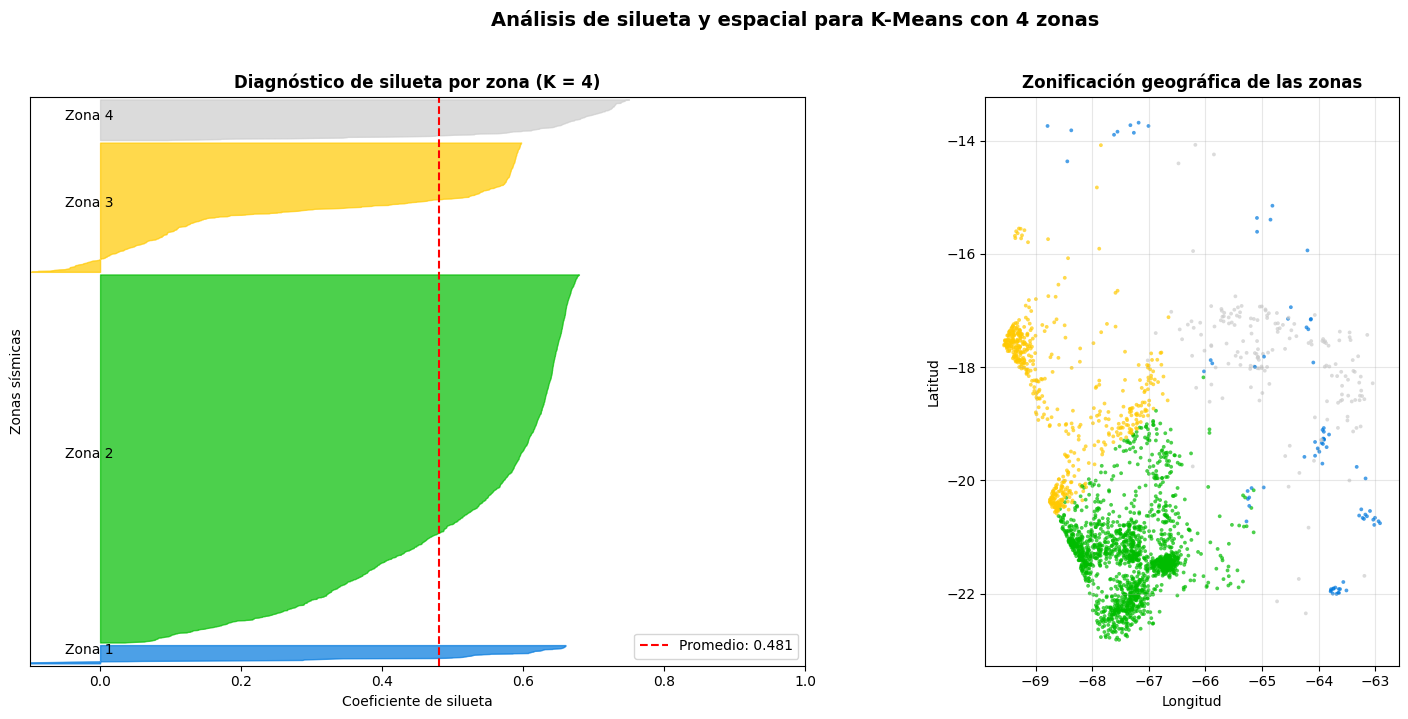

In [34]:
import matplotlib.cm as cm
from sklearn.metrics import silhouette_samples
n_clusters = K_OPTIMO
cluster_labels = datos_filtrados["zona_kmeans"].values
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))
# GRÁFICO 1: Diagnóstico de silueta (izquierda)
ax1.set_xlim([-0.1, 1])
ax1.set_ylim([0, len(X) + (n_clusters + 1) * 10])

sample_silhouette_values = silhouette_samples(X, cluster_labels)
silhouette_avg = silhouette_score(X, cluster_labels)

y_lower = 10
# Se itera sobre las zonas con numeración canónica (1 a K)
for i in range(1, n_clusters + 1):
    ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
    ith_cluster_silhouette_values.sort()
    size_cluster_i = ith_cluster_silhouette_values.shape[0]
    y_upper = y_lower + size_cluster_i

    color = cm.nipy_spectral(float(i) / n_clusters)
    ax1.fill_betweenx(
        np.arange(y_lower, y_upper), 0, ith_cluster_silhouette_values,
        facecolor=color, edgecolor=color, alpha=0.7,
    )
    ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, f"Zona {i}")
    y_lower = y_upper + 10

ax1.set_title(f"Diagnóstico de silueta por zona (K = {n_clusters})", fontweight="bold")
ax1.set_xlabel("Coeficiente de silueta")
ax1.set_ylabel("Zonas sísmicas")
ax1.axvline(x=silhouette_avg, color="red", linestyle="--", label=f"Promedio: {silhouette_avg:.3f}")
ax1.set_yticks([])
ax1.legend(loc="lower right")
# GRÁFICO 2: Mapa geográfico (derecha)
colors = cm.nipy_spectral(cluster_labels.astype(float) / n_clusters)
ax2.scatter(
    datos_filtrados["longitud"], datos_filtrados["latitud"],
    marker=".", s=30, lw=0, alpha=0.7, c=colors, edgecolor="k"
)
ax2.set_title("Zonificación geográfica de las zonas", fontweight="bold")
ax2.set_xlabel("Longitud")
ax2.set_ylabel("Latitud")
ax2.set_aspect("equal")
ax2.grid(alpha=0.3)

plt.suptitle(
    f"Análisis de silueta y espacial para K-Means con {n_clusters} zonas",
    fontsize=14, fontweight="bold", y=1.02
)
plt.tight_layout()
guardar_figura(fig, "figura_12_diagnostico_silueta")
plt.show()


In [35]:
import shutil

shutil.make_archive("resultados", "zip", root_dir=".", base_dir="resultados")
print("Figuras:", sorted(os.listdir("resultados/figuras")))
print("Tablas:", sorted(os.listdir("resultados/tablas")))
print(f"Catalogo crudo: {os.path.getsize('resultados/catalogo_crudo_usgs.csv')} bytes")


Figuras: ['figura_01_histograma_magnitudes.png', 'figura_02_sismos_por_anio.png', 'figura_03_histograma_profundidades.png', 'figura_04_mapa_catalogo_completo.png', 'figura_05_metodo_codo.png', 'figura_06_indice_silueta.png', 'figura_07_dendrograma_ward.png', 'figura_08_mapa_kmeans.png', 'figura_09_mapa_ward.png', 'figura_10_matriz_concordancia.png', 'figura_11_mapa_comparativo.png', 'figura_12_diagnostico_silueta.png']
Tablas: ['tabla_01_resumen_catalogo.tex', 'tabla_02_estadisticos_descriptivos.tex', 'tabla_03_filtro_catalogo.tex', 'tabla_04_verificacion_estandarizacion.tex', 'tabla_04b_indice_morisita.tex', 'tabla_05_seleccion_k.tex', 'tabla_06_tamanos_clusters.tex', 'tabla_07_centroides_kmeans.tex', 'tabla_08_ari.tex', 'tabla_09_concordancia_kmeans_ward.tex', 'tabla_10_resumen_zonas.tex', 'tabla_11_resumen_pipeline.tex']
Catalogo crudo: 1626394 bytes
